In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import html
import re
import json
import urllib.request
import xml.etree.ElementTree as ET
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROCESSED = ROOT / "data/raw", ROOT / "data/processed"
for directory in [RAW / "faostat", RAW / "worldbank", RAW / "un", PROCESSED]:
    directory.mkdir(parents=True, exist_ok=True)
START, END = 2000, 2023
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
sources = {
    "un_m49": {
        "url": "https://unstats.un.org/unsd/methodology/m49/overview/",
        "path": "un/m49_overview.html",
        "purpose": "M49 to ISO3 country-code crosswalk",
    },
    "faostat": {
        "url": "https://bulks-faostat.fao.org/production/Production_Crops_Livestock_E_All_Data_(Normalized).zip",
        "path": "faostat/Production_Crops_Livestock_E_All_Data_(Normalized).zip",
        "documentation": "https://www.fao.org/faostat/en/#data/QCL",
        "licence": "CC-BY-4.0; FAO Statistical Database Terms of Use",
        "licence_url": "https://www.fao.org/contact-us/terms/db-terms-of-use/en/",
    },
    "faostat_catalog": {
        "url": "https://bulks-faostat.fao.org/production/datasets_E.xml",
        "path": "faostat/datasets_E.xml",
    },
    "worldbank": {
        "url": "https://cckpapi.worldbank.org/cckp/v1/era5-x0.25_timeseries_pr,tas_timeseries_annual_1950-2025_mean_historical_era5_x0.25_mean/all_countries?_format=json",
        "path": "worldbank/era5_annual_1950_2025.json",
        "documentation": "https://climateknowledgeportal.worldbank.org/download-data",
        "metadata": "https://climateknowledgeportal.worldbank.org/index.php/metadata",
        "licence": "World Bank dataset terms; check third-party ERA5 attribution",
        "licence_url": "https://www.worldbank.org/en/about/legal/terms-of-use-for-datasets",
        "attribution": "World Bank Climate Change Knowledge Portal; ERA5, Copernicus/ECMWF",
        "units": {"tas": "degC, annual mean", "pr": "mm, annual accumulated precipitation"},
        "spatial_aggregation": "country area, not coffee-growing area",
    },
}
manifest_path = RAW / "sources.json"
previous = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
for name, source in sources.items():
    path = RAW / source["path"]
    downloaded = not path.exists()
    if downloaded:
        request = urllib.request.Request(source["url"], headers={"User-Agent": "Mozilla/5.0", "Accept": "*/*"})
        with urllib.request.urlopen(request, timeout=60) as response:
            payload = response.read()
        temporary = path.with_suffix(path.suffix + ".part")
        temporary.write_bytes(payload)
        temporary.replace(path)
    source["downloaded_at_utc"] = (datetime.now(timezone.utc).isoformat() if downloaded
                                   else previous.get(name, {}).get("downloaded_at_utc", datetime.now(timezone.utc).isoformat()))
    source["bytes"] = path.stat().st_size
    source["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()

assert zipfile.is_zipfile(RAW / sources["faostat"]["path"])
climate_raw = json.loads((RAW / sources["worldbank"]["path"]).read_text())
assert climate_raw["metadata"]["status"] == "success"
assert {"tas", "pr"} <= climate_raw["data"].keys()
catalog = ET.parse(RAW / sources["faostat_catalog"]["path"]).getroot()
sources["faostat"]["last_updated"] = next(d.findtext("DateUpdate") for d in catalog if d.findtext("DatasetCode") == "QCL")
manifest_path.write_text(json.dumps(sources, ensure_ascii=False, indent=2) + "\n")
display(pd.DataFrame(sources).T[["path", "bytes", "downloaded_at_utc"]])

,path,bytes,downloaded_at_utc
un_m49,un/m49_overview.html,1721575,2026-11-09T21:15:24.619472+00:00
faostat,faostat/Production_Crops_Livestock_E_All_Data_...,33921825,2026-11-09T21:07:50Z
faostat_catalog,faostat/datasets_E.xml,115952,2026-11-09T21:07:50Z
worldbank,worldbank/era5_annual_1950_2025.json,622696,2026-11-09T21:07:50Z


In [3]:
with zipfile.ZipFile(RAW / sources["faostat"]["path"]) as archive:
    flags_dictionary = pd.read_csv(archive.open("Production_Crops_Livestock_E_Flags.csv"))
    csv_name = "Production_Crops_Livestock_E_All_Data_(Normalized).csv"
    with archive.open(csv_name) as stream:
        coffee = pd.concat(
            [chunk.loc[chunk["Item"].eq("Coffee, green")]
             for chunk in pd.read_csv(stream, chunksize=200_000, low_memory=False,
                                      dtype={"Area Code (M49)": "string", "Flag": "string", "Note": "string"})],
            ignore_index=True,
        )
coffee.to_csv(PROCESSED / "faostat_coffee_all.csv", index=False)
assert coffee.loc[coffee["Element"].eq("Production"), "Unit"].eq("t").all()
assert coffee.loc[coffee["Element"].eq("Area harvested"), "Unit"].eq("ha").all()
assert coffee.loc[coffee["Element"].eq("Yield"), "Unit"].eq("kg/ha").all()
display(flags_dictionary)
display(coffee.groupby("Element").agg(rows=("Value", "size"), missing=("Value", lambda s: s.isna().sum()),
                                      first_year=("Year", "min"), last_year=("Year", "max")))

,Flag,Description
0,A,Official figure
1,E,Estimated value
2,I,Value imputed by a receiving agency
3,M,Missing value; data cannot exist
4,X,Figure from external organization


,rows,missing,first_year,last_year
Element,,,,
Area harvested,6751,122,1961,2024
Production,6979,214,1961,2024
Yield,6479,0,1961,2024


In [4]:
m49_html = (RAW / sources["un_m49"]["path"]).read_text()
table = re.search(r'<table\b[^>]*id\s*=\s*"downloadTableEN"[^>]*>(.*?)</table>', m49_html, re.S).group(1)
table = re.sub(r"<!--.*?-->", "", table, flags=re.S)
m49_to_iso3 = {}
for row in re.findall(r"<tr\b[^>]*>(.*?)</tr>", table, re.S):
    cells = [html.unescape(re.sub(r"<[^>]+>", "", cell)).strip()
             for cell in re.findall(r"<td\b[^>]*>(.*?)</td>", row, re.S)]
    if len(cells) >= 12 and re.fullmatch(r"[A-Z]{3}", cells[11]):
        m49_to_iso3[cells[9]] = cells[11]
# The UN table omits Taiwan; FAOSTAT and CCKP publish it separately.
m49_to_iso3["158"] = "TWN"
assert m49_to_iso3["076"] == "BRA" and m49_to_iso3["156"] == "CHN"

# FAO code 351 aggregates mainland China and territories; use the separate areas.
national = coffee.loc[coffee["Area Code"].lt(5000) & coffee["Area Code"].ne(351)]
producers = national.loc[national["Element"].eq("Production") & national["Year"].between(START, END)
                         & national["Value"].gt(0), "Area"].unique()
selected = national.loc[national["Area"].isin(producers) & national["Year"].between(START - 1, END)].copy()
selected["iso3"] = selected["Area Code (M49)"].str.lstrip("'").str.zfill(3).map(m49_to_iso3)
assert selected["iso3"].notna().all(), selected.loc[selected["iso3"].isna(), "Area"].unique()
countries = selected[["Area", "iso3"]].drop_duplicates().rename(columns={"Area": "country"})
assert countries["iso3"].is_unique
countries.to_csv(PROCESSED / "countries.csv", index=False)
assert not selected.duplicated(["iso3", "Year", "Element"]).any()
index = ["iso3", "Year"]
values = selected.pivot(index=index, columns="Element", values="Value").rename(columns={
    "Production": "production_t", "Area harvested": "area_ha", "Yield": "yield_kg_ha"})
flags = selected.pivot(index=index, columns="Element", values="Flag").rename(columns={
    "Production": "production_flag", "Area harvested": "area_flag", "Yield": "yield_flag"})
grid = pd.MultiIndex.from_product([countries["iso3"], range(START - 1, END + 1)], names=index)
production = values.join(flags).reindex(grid).reset_index().rename(columns={"Year": "year"})
production.columns.name = None
production = production.merge(countries, on="iso3", validate="many_to_one").sort_values(["iso3", "year"])
for column, output in [("production_t", "production_yoy_pct"), ("yield_kg_ha", "yield_yoy_pct")]:
    previous_value = production.groupby("iso3")[column].shift()
    production[output] = (production[column] / previous_value - 1).where(previous_value.gt(0)) * 100
production = production.loc[production["year"].between(START, END)].copy()
assert len(production) == len(countries) * (END - START + 1)
assert production[["production_t", "area_ha", "yield_kg_ha"]].ge(0).where(production[["production_t", "area_ha", "yield_kg_ha"]].notna(), True).all().all()
check = production.dropna(subset=["production_t", "area_ha", "yield_kg_ha"])
check = check.loc[check["area_ha"].gt(0)]
computed_yield = check["production_t"] / check["area_ha"] * 1000
production["yield_identity_review"] = False
production.loc[check.index, "yield_identity_review"] = ~np.isclose(
    check["yield_kg_ha"], computed_yield, rtol=0.05, atol=0.1)
yield_issues = check.loc[production.loc[check.index, "yield_identity_review"],
                         ["country", "year", "production_t", "area_ha", "yield_kg_ha"]].copy()
yield_issues["yield_calculated_kg_ha"] = yield_issues["production_t"] / yield_issues["area_ha"] * 1000
yield_issues.to_csv(PROCESSED / "yield_identity_for_review.csv", index=False)
production.to_csv(PROCESSED / "coffee_production.csv", index=False)
display(production.groupby("country").agg(years_with_production=("production_t", "count"),
                                         years_with_yield=("yield_kg_ha", "count")))

,years_with_production,years_with_yield
country,,
Angola,24,24
Belize,24,24
Benin,24,24
Bolivia (Plurinational State of),24,24
Brazil,24,24
...,...,...
Venezuela (Bolivarian Republic of),24,24
Viet Nam,24,24
Yemen,24,24


In [5]:
climate_records = [
    {"iso3": iso3, "year": int(timestamp[:4]), "variable": variable, "value": value}
    for variable in ["tas", "pr"]
    for iso3, observations in climate_raw["data"][variable].items()
    if iso3 in set(production["iso3"])
    for timestamp, value in observations.items()
    if 1991 <= int(timestamp[:4]) <= END
]
climate_long = pd.DataFrame(climate_records)
assert not climate_long.duplicated(["iso3", "year", "variable"]).any()
climate = climate_long.pivot(index=["iso3", "year"], columns="variable", values="value").reset_index()
climate = climate.rename(columns={"tas": "temperature_c", "pr": "precipitation_mm"})
climate.columns.name = None
assert len(climate) == len(countries) * (END - 1991 + 1)
assert climate[["temperature_c", "precipitation_mm"]].notna().all().all()
baseline = (climate.loc[climate["year"].between(1991, 2020)].groupby("iso3")
            .agg(temperature_baseline_c=("temperature_c", "mean"), precipitation_baseline_mm=("precipitation_mm", "mean")))
climate = climate.merge(baseline, on="iso3", validate="many_to_one")
climate["temperature_anomaly_c"] = climate["temperature_c"] - climate["temperature_baseline_c"]
climate["precipitation_anomaly_pct"] = (climate["precipitation_mm"] / climate["precipitation_baseline_mm"] - 1) * 100
climate.to_csv(PROCESSED / "climate_annual.csv", index=False)
data = production.merge(climate, on=["iso3", "year"], how="left", validate="one_to_one", indicator=True)
assert data["_merge"].eq("both").all()
data = data.drop(columns="_merge").sort_values(["iso3", "year"]).reset_index(drop=True)
assert not data.duplicated(["iso3", "year"]).any()
assert data.groupby("iso3")["year"].nunique().eq(END - START + 1).all()
assert data[["iso3", "year", "temperature_c", "precipitation_mm"]].notna().all().all()
assert data["temperature_c"].between(-50, 60).all() and data["precipitation_mm"].ge(0).all()
required = ["production_t", "area_ha", "yield_kg_ha", "temperature_c", "precipitation_mm"]
coverage = data.groupby(["iso3", "country"])[required].count().reset_index()
coverage["complete"] = coverage[required].eq(END - START + 1).all(axis=1)
world_production = coffee.loc[coffee["Area"].eq("World") & coffee["Element"].eq("Production")].set_index("Year")["Value"]
shares = data["production_t"] / data["year"].map(world_production) * 100
max_share = shares.groupby(data["iso3"]).max().rename("max_world_share_pct")
excluded = coverage.loc[~coverage["complete"]].merge(max_share, on="iso3", validate="one_to_one")
# Stop for review if an incomplete country accounts for at least 1% of global production in any observed year.
assert excluded["max_world_share_pct"].lt(1).all(), excluded.loc[excluded["max_world_share_pct"].ge(1)]
excluded.to_csv(PROCESSED / "excluded_countries.csv", index=False)
display(excluded)
complete_iso3 = coverage.loc[coverage["complete"], "iso3"]
data = data.loc[data["iso3"].isin(complete_iso3)].reset_index(drop=True)
assert data[required].notna().all().all()
assert len(data) == len(complete_iso3) * (END - START + 1)
countries = countries.loc[countries["iso3"].isin(complete_iso3)]
production = production.loc[production["iso3"].isin(complete_iso3)]
climate = climate.loc[climate["iso3"].isin(complete_iso3)]
selected = selected.loc[selected["iso3"].isin(complete_iso3)]
yield_issues = yield_issues.loc[yield_issues["country"].isin(countries["country"])]
countries.to_csv(PROCESSED / "countries.csv", index=False)
production.to_csv(PROCESSED / "coffee_production.csv", index=False)
climate.to_csv(PROCESSED / "climate_annual.csv", index=False)
yield_issues.to_csv(PROCESSED / "yield_identity_for_review.csv", index=False)
for _, group in data.groupby("iso3"):
    for column in ["yield_kg_ha", "temperature_c", "precipitation_mm"]:
        valid = group.dropna(subset=[column])
        if len(valid) < 3:
            continue
        trend = np.polyval(np.polyfit(valid["year"] - START, valid[column], 1), valid["year"] - START)
        data.loc[valid.index, column + "_detrended"] = valid[column] - trend
        if column == "yield_kg_ha":
            data.loc[valid.index, "yield_deviation_pct"] = np.divide(
                valid[column] - trend, trend, out=np.full(len(trend), np.nan), where=trend > 0) * 100
data["production_jump_review"] = data["production_yoy_pct"].abs().gt(50)
assert not np.isinf(data.select_dtypes(include="number").to_numpy()).any()
missing = data.loc[data[["production_t", "area_ha", "yield_kg_ha"]].isna().any(axis=1),
                   ["country", "iso3", "year", "production_t", "area_ha", "yield_kg_ha"]]
missing.to_csv(PROCESSED / "missing_production_data.csv", index=False)
data.to_csv(PROCESSED / "coffee_climate.csv", index=False)
display(pd.Series({"countries": data["iso3"].nunique(), "first_year": data["year"].min(),
                   "last_year": data["year"].max(), "rows": len(data), "rows_with_production": int(data["production_t"].notna().sum()),
                   "rows_with_yield": int(data["yield_kg_ha"].notna().sum()),
                   "rows_missing_any_production_measure": len(missing),
                   "duplicate_keys": int(data.duplicated(["iso3", "year"]).sum()), "join_match_pct": 100.0}))

,iso3,country,production_t,area_ha,yield_kg_ha,temperature_c,precipitation_mm,complete,max_world_share_pct
0,COK,Cook Islands,24,24,21,24,24,False,0.00
1,CPV,Cabo Verde,13,13,13,24,24,False,0.00
2,GLP,Guadeloupe,7,7,7,24,24,False,0.00
3,MTQ,Martinique,7,7,7,24,24,False,0.00
4,SAU,Saudi Arabia,1,1,1,24,24,False,0.01
5,TWN,"China, Taiwan Province of",24,24,9,24,24,False,0.01


countries                                75.00
first_year                            2,000.00
last_year                             2,023.00
rows                                  1,800.00
rows_with_production                  1,800.00
rows_with_yield                       1,800.00
rows_missing_any_production_measure       0.00
duplicate_keys                            0.00
join_match_pct                          100.00
dtype: float64

In [6]:
latest = data.loc[data["year"].eq(END)].copy()
world = coffee.loc[coffee["Area"].eq("World") & coffee["Element"].eq("Production")].set_index("Year")["Value"]
latest["world_share_pct"] = latest["production_t"] / world.loc[END] * 100
summary = data.groupby(["iso3", "country"]).agg(
    years_with_production=("production_t", "count"), years_with_yield=("yield_kg_ha", "count"),
    mean_production_t=("production_t", "mean"), mean_yield_kg_ha=("yield_kg_ha", "mean"),
    yield_cv_pct=("yield_kg_ha", lambda x: x.std(ddof=1) / x.mean() * 100),
    detrended_yield_std_pct=("yield_deviation_pct", lambda x: x.std(ddof=1)),
    production_drop_gt10_pct=("production_yoy_pct", lambda x: x.dropna().lt(-10).mean() * 100),
    min_production_yoy_pct=("production_yoy_pct", "min"),
    official_production_pct=("production_flag", lambda x: x.loc[x.isin(["A", "E", "I", "X"])].eq("A").mean() * 100),
    production_jumps_for_review=("production_jump_review", "sum"),
).reset_index()
summary = summary.merge(latest[["iso3", "production_t", "yield_kg_ha", "world_share_pct"]], on="iso3", how="left", validate="one_to_one")
summary = summary.sort_values("production_t", ascending=False)
summary.to_csv(PROCESSED / "country_summary.csv", index=False)
quality_flags = selected.loc[selected["Year"].between(START, END)].groupby(["Element", "Flag"]).size().rename("rows").reset_index()
quality_flags.to_csv(PROCESSED / "quality_flags.csv", index=False)
quality_issues = data.loc[data["production_jump_review"], ["country", "year", "production_t", "production_yoy_pct", "production_flag"]]
quality_issues.to_csv(PROCESSED / "production_jumps_for_review.csv", index=False)
display(summary[["country", "production_t", "world_share_pct", "yield_cv_pct", "detrended_yield_std_pct", "official_production_pct"]].head(10))
display(quality_flags)
display(quality_issues)
print(f"Udział wszystkich uwzględnionych krajów i terytoriów w światowych zbiorach {END}: {latest['world_share_pct'].sum():.2f}%")

,country,production_t,world_share_pct,yield_cv_pct,detrended_yield_std_pct,official_production_pct
5,Brazil,"3,348,510.00",30.19,25.46,9.28,100.00
69,Viet Nam,"1,956,782.46",17.64,19.02,7.72,87.50
29,Indonesia,"758,725.00",6.84,9.70,4.38,100.00
12,Colombia,"680,857.67",6.14,15.12,15.10,100.00
19,Ethiopia,"559,400.00",5.04,10.86,10.52,62.50
65,Uganda,"468,000.00",4.22,15.03,12.38,100.00
27,Honduras,"384,361.02",3.46,14.96,8.97,100.00
48,Peru,"366,940.03",3.31,11.05,10.07,100.00
30,India,"360,500.00",3.25,8.60,5.26,100.00
6,Central African Republic,"316,108.00",2.85,25.66,22.43,45.83


,Element,Flag,rows
0,Area harvested,A,783
1,Area harvested,E,437
2,Area harvested,I,570
3,Area harvested,X,10
4,Production,A,1071
5,Production,E,204
6,Production,I,339
7,Production,X,186
8,Yield,A,770
9,Yield,E,1021


,country,year,production_t,production_yoy_pct,production_flag
2,Angola,2002,"1,260.00",-61.82,X
3,Angola,2003,"2,040.00",61.90,X
5,Angola,2005,"3,500.00",76.77,E
7,Angola,2007,"11,523.00",130.46,A
8,Angola,2008,"4,000.00",-65.29,A
...,...,...,...,...,...
1734,Yemen,2006,"17,292.00",52.61,A
1749,Yemen,2021,"41,933.49",95.56,X
1753,Zambia,2001,"5,868.00",166.73,A
1760,Zambia,2008,"6,584.09",91.85,I


Udział wszystkich uwzględnionych krajów i terytoriów w światowych zbiorach 2023: 99.98%


In [7]:
correlation_rows = []
for iso3, group in data.groupby("iso3"):
    result = {"iso3": iso3, "country": group["country"].iloc[0]}
    for variable, label in [("temperature_c", "temperature"), ("precipitation_mm", "precipitation")]:
        paired = group[["yield_kg_ha_detrended", variable + "_detrended"]].dropna()
        result[label + "_paired_years"] = len(paired)
        enough_data = len(paired) >= 10 and paired.std().gt(1e-8).all()
        result["yield_" + label + "_r"] = paired.iloc[:, 0].corr(paired.iloc[:, 1]) if enough_data else np.nan
    correlation_rows.append(result)
correlations = pd.DataFrame(correlation_rows)
assert len(correlations) == len(countries)
assert correlations[["yield_temperature_r", "yield_precipitation_r"]].abs().le(1).where(
    correlations[["yield_temperature_r", "yield_precipitation_r"]].notna(), True).all().all()
assert correlations.loc[correlations["temperature_paired_years"].lt(10), "yield_temperature_r"].isna().all()
assert correlations.loc[correlations["precipitation_paired_years"].lt(10), "yield_precipitation_r"].isna().all()
correlations.to_csv(PROCESSED / "climate_correlations.csv", index=False)
display(correlations.sort_values("yield_precipitation_r", ascending=False))
display(summary.loc[summary["years_with_yield"].ge(10),
                    ["country", "years_with_yield", "detrended_yield_std_pct", "official_production_pct", "production_jumps_for_review"]]
        .sort_values("detrended_yield_std_pct").head(5))

,iso3,country,temperature_paired_years,yield_temperature_r,precipitation_paired_years,yield_precipitation_r
31,JAM,Jamaica,24,-0.14,24,0.60
56,SLV,El Salvador,24,-0.65,24,0.49
39,MMR,Myanmar,24,-0.09,24,0.44
70,VUT,Vanuatu,24,0.08,24,0.40
61,TLS,Timor-Leste,24,0.06,24,0.38
...,...,...,...,...,...,...
3,BLZ,Belize,24,-0.04,24,-0.35
36,LKA,Sri Lanka,24,0.08,24,-0.38
12,COL,Colombia,24,0.27,24,-0.40
40,MOZ,Mozambique,24,0.17,24,-0.50


,country,years_with_yield,detrended_yield_std_pct,official_production_pct,production_jumps_for_review
16,Dominica,24,0.37,20.83,2
28,Haiti,24,0.56,37.50,2
24,Equatorial Guinea,24,0.86,0.00,0
13,Comoros,24,1.10,0.00,0
47,Panama,24,1.15,91.67,1


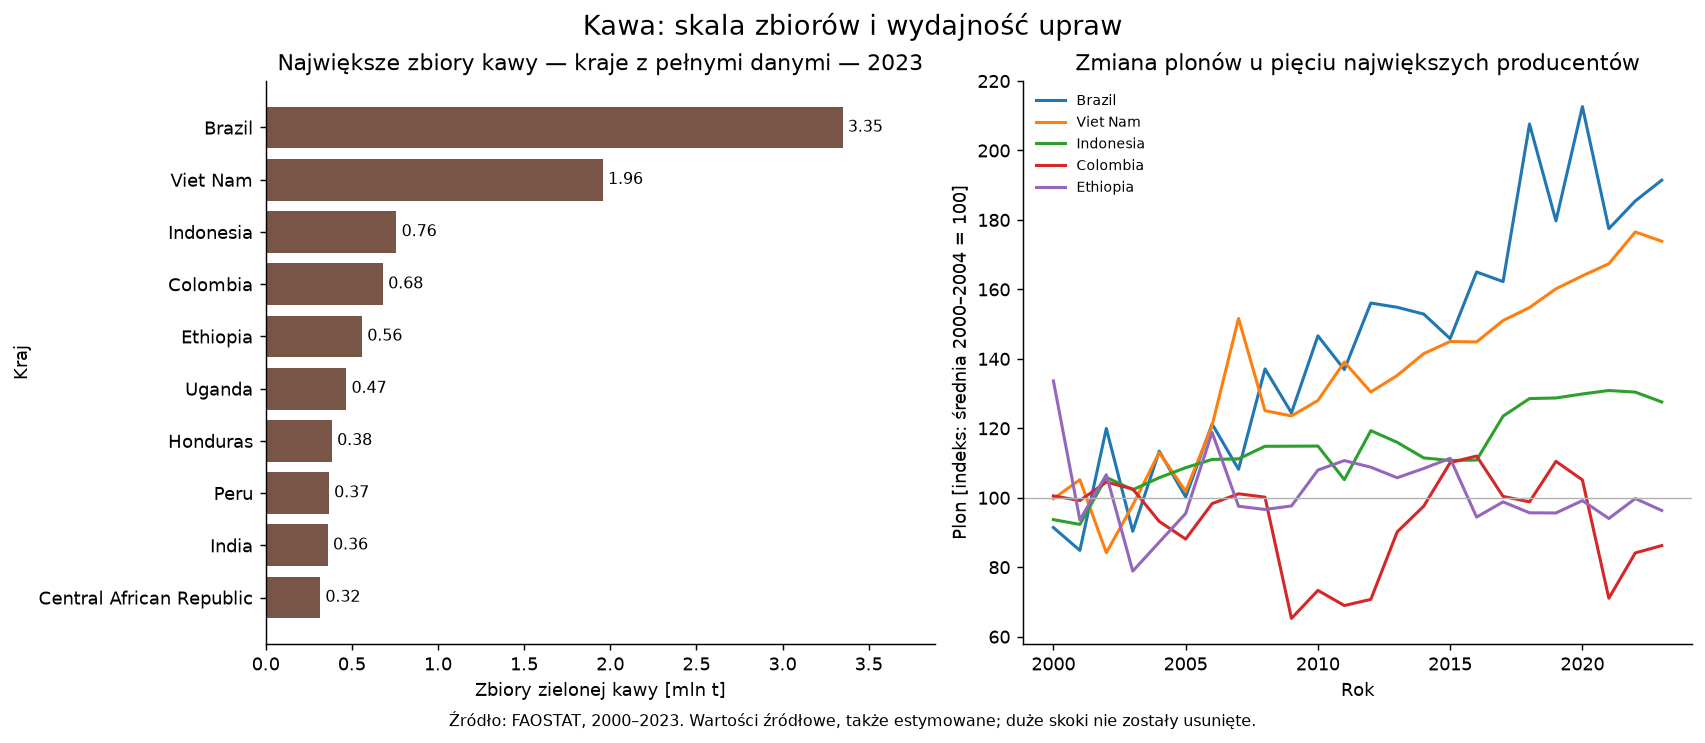

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")
top = latest.nlargest(10, "production_t").sort_values("production_t")
axes[0].barh(top["country"], top["production_t"] / 1_000_000, color="#795548")
axes[0].set(title=f"Największe zbiory kawy — kraje z pełnymi danymi — {END}", xlabel="Zbiory zielonej kawy [mln t]", ylabel="Kraj")
for i, value in enumerate(top["production_t"] / 1_000_000):
    axes[0].text(value + 0.03, i, f"{value:.2f}", va="center", fontsize=9)
axes[0].set_xlim(0, top["production_t"].max() / 1_000_000 * 1.16)
leaders = latest.nlargest(5, "production_t")["iso3"]
for iso3 in leaders:
    group = data.loc[data["iso3"].eq(iso3)]
    base_yield = group.loc[group["year"].between(START, START + 4), "yield_kg_ha"].mean()
    axes[1].plot(group["year"], group["yield_kg_ha"] / base_yield * 100,
                 label=group["country"].iloc[0], linewidth=1.7)
axes[1].axhline(100, color="0.7", linewidth=0.8)
axes[1].set(title="Zmiana plonów u pięciu największych producentów", xlabel="Rok", ylabel="Plon [indeks: średnia 2000–2004 = 100]")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Kawa: skala zbiorów i wydajność upraw", fontsize=15)
fig.supxlabel("Źródło: FAOSTAT, 2000–2023. Wartości źródłowe, także estymowane; duże skoki nie zostały usunięte.", fontsize=9)
fig.savefig(PROCESSED / "coffee_overview.png", dpi=160, bbox_inches="tight")
plt.show()

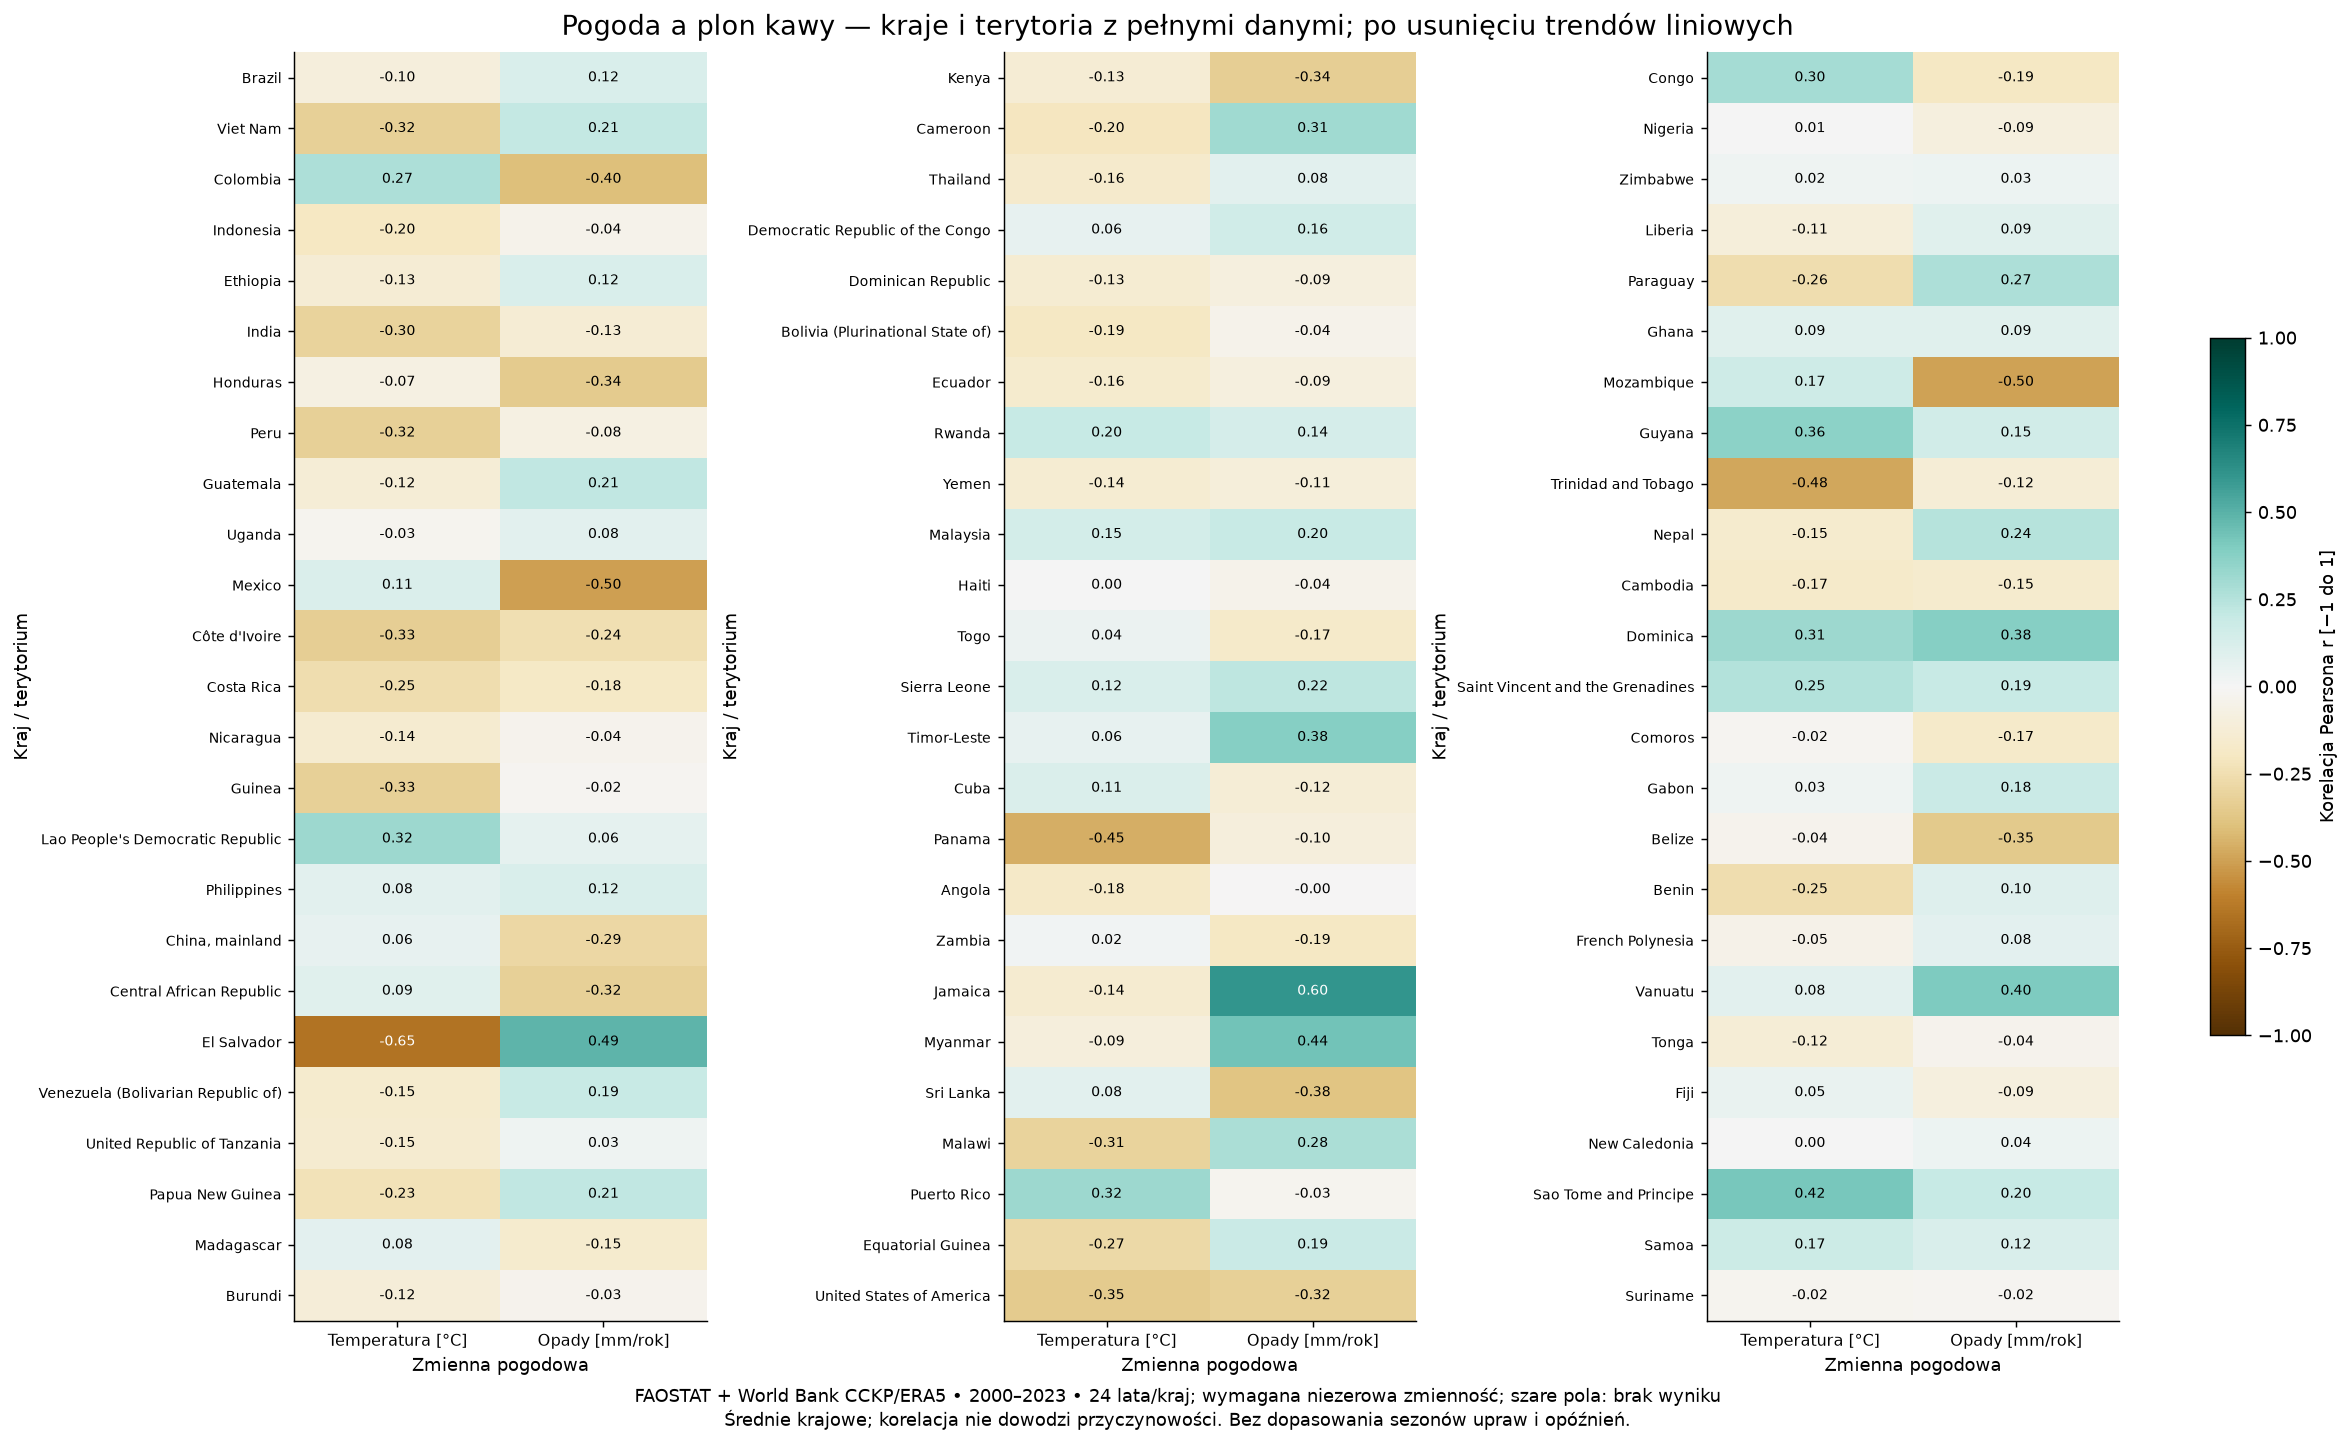

In [9]:
plot = correlations.set_index("country")[["yield_temperature_r", "yield_precipitation_r"]]
plot = plot.loc[data.groupby("country")["production_t"].mean().sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 3, figsize=(18, 11), layout="constrained")
cmap = plt.get_cmap("BrBG").copy()
cmap.set_bad("#dddddd")
for ax, positions in zip(axes, np.array_split(np.arange(len(plot)), 3)):
    section = plot.iloc[positions]
    image = ax.imshow(section.to_numpy(dtype=float), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    ax.set_yticks(range(len(section)), section.index, fontsize=8)
    ax.set_xticks([0, 1], ["Temperatura [°C]", "Opady [mm/rok]"], fontsize=9)
    ax.set(xlabel="Zmienna pogodowa", ylabel="Kraj / terytorium")
    for row in range(len(section)):
        for col in range(2):
            value = section.iloc[row, col]
            ax.text(col, row, f"{value:.2f}" if pd.notna(value) else "—", ha="center", va="center",
                    color="white" if abs(value) > 0.6 else "black", fontsize=8)
fig.colorbar(image, ax=list(axes), label="Korelacja Pearsona r [−1 do 1]", shrink=0.55)
fig.suptitle("Pogoda a plon kawy — kraje i terytoria z pełnymi danymi; po usunięciu trendów liniowych", fontsize=15)
fig.supxlabel("FAOSTAT + World Bank CCKP/ERA5 • 2000–2023 • 24 lata/kraj; wymagana niezerowa zmienność; szare pola: brak wyniku\nŚrednie krajowe; korelacja nie dowodzi przyczynowości. Bez dopasowania sezonów upraw i opóźnień.", fontsize=10)
fig.savefig(PROCESSED / "coffee_climate_correlations.png", dpi=160, bbox_inches="tight")
plt.show()